## 1. Assignment -6-
**Linear and Ligistic Regressions- Bike Demand Modeling in ML Systems**

## 2. Context & Scenario
You are advising a city mobility operations team responsible for staffing and rebalancing a bike-sharing system. Your objective is to build a reproducible, deployment-oriented modeling workflow that supports (i) **hourly demand forecasting** and (ii) **high-demand alerting**. You will implement leakage-resistant preprocessing, evaluate models with appropriate metrics and diagnostics, and articulate monitoring and reliability considerations expected in production ML systems.

## 3. Dataset
Use the **Bike Sharing Dataset (UCI Machine Learning Repository)**, specifically `hour.csv`.
- Download ZIP: https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip
- License: **CC BY 4.0**

The file contains hourly rental counts with weather and calendar features. Define two targets:
- **Regression target:** `cnt` (total rentals, continuous).
- **Classification target:** `high_demand = 1[cnt > median(cnt)]` (binary), justified as an operational alert threshold.

## 4. Machine Learning Tasks
- **Data ingestion and validation:** Load `hour.csv`; document schema expectations; implement basic validation checks (missingness, plausible ranges).
- **Exploratory analysis:** Provide at least **two plots** (at least one using **matplotlib**) and concise interpretations relevant to modeling and operational risk.
- **Preprocessing and leakage control:** Use `Pipeline` + `ColumnTransformer` to ensure imputation, scaling, and encoding are **fit on training data only**.
- **Linear regression:** Train a baseline `LinearRegression`; report **RMSE** and **R²**; include at least **one diagnostic plot** (e.g., residuals vs fitted or predicted vs actual) and interpret failure modes.
- **Regularized improvement:** Train `RidgeCV` or `LassoCV` (or equivalent CV search) and compare generalization against baseline.
- **Logistic regression:** Train `LogisticRegression` with probability outputs; evaluate with **ROC AUC**, **confusion matrix**, and **classification report**.
- **Threshold tuning:** Evaluate multiple thresholds and select a deploy threshold aligned with an explicit operational objective (e.g., recall-driven alerting).
- **ML systems emphasis (written answers):** Provide a brief plan for reproducibility artifacts (seeds, data/versioning), inference cost considerations (dimensionality/latency), and monitoring for drift/performance regression.

## 5. Deliverables
- Executed Jupyter notebook with code, plots, and brief Markdown interpretations.
- Short written answers embedded in Markdown cells.
- Optional appendix cell: experiment log table (parameters, seeds, metrics, timestamps).

## Grading Rubric (100 points)
- **Code correctness & execution — 30 pts** (notebook runs end-to-end; correct use of numpy/pandas/scikit-learn; metrics computed correctly; plots render).
- **Data validation & EDA quality — 15 pts** (meaningful validation gates; at least two relevant plots with clear labels; interpretations tied to modeling risk).
- **Preprocessing & leakage control — 15 pts** (proper Pipeline + ColumnTransformer; transformations fit only on training data; robust handling of categorical levels).
- **Regression modeling & diagnostics — 15 pts** (baseline regression with RMSE/R²; at least one diagnostic plot; coherent error analysis and implications).
- **Regularization improvement & comparison — 10 pts** (Ridge/Lasso with cross-validation implemented; justified model choice using validation results and tradeoffs).
- **Classification evaluation & thresholding — 10 pts** (ROC AUC with confusion matrix/report; threshold sweep; deployed threshold justified by objective or cost tradeoff).
- **ML systems thinking & reproducibility — 5 pts** (clear reproducibility artifacts, monitoring/drift plan, and inference cost considerations).
- **Limitations & next steps — embedded (0–5 pts)** (credible limitations and concrete follow-up experiments assessed within the relevant categories above).

_________________________________________________________________________________________________________________________________________________________________________________

## Linear and Logistic Regressions: Bike Demand Modeling in ML Systems

This assignment uses bike-sharing data to predict hourly demand and identify high-demand hours.

## Context & Scenario

The goal is to predict bike demand and identify hours when demand is higher than normal. I will use linear regression for demand prediction and logistic regression for high-demand classification.

## Dataset

This assignment uses the UCI Bike Sharing Dataset and the `hour.csv` file. The regression target is `cnt`, or total rentals. For classification, `high_demand` is 1 when `cnt` is above the median and 0 otherwise.

In [1]:
# Reproducibility and core libraries

import os
os.environ["OMP_NUM_THREADS"] = "1"

import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LogisticRegression
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Random seed:", RANDOM_STATE)
print("pandas version:", pd.__version__)

Random seed: 42
pandas version: 2.3.3


## Data Ingestion

The dataset is loaded directly from the UCI repository.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip"

with urllib.request.urlopen(DATA_URL) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    hour_file = [name for name in z.namelist() if name.endswith("hour.csv")][0]
    with z.open(hour_file) as f:
        bike = pd.read_csv(f)

print("Dataset shape:", bike.shape)
print("\nColumns:")
print(bike.columns.tolist())

bike.head()

Dataset shape: (17379, 17)

Columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.240,0.288,0.810,0.000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.220,0.273,0.800,0.000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.220,0.273,0.800,0.000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.240,0.288,0.750,0.000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.240,0.288,0.750,0.000,0,1,1


## Schema Expectations

The dataset contains hourly bike rentals, weather information, and calendar information. I will not use `casual` or `registered` as features because they are part of `cnt` and would cause target leakage.

In [3]:
expected_columns = [
    "instant",
    "dteday",
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
]

missing_columns = [col for col in expected_columns if col not in bike.columns]

assert len(missing_columns) == 0, f"Missing expected columns: {missing_columns}"

print("All expected columns are present.")
print("Number of rows:", len(bike))
print("Number of columns:", len(bike.columns))

All expected columns are present.
Number of rows: 17379
Number of columns: 17


## Data Validation

I checked for missing values, duplicate rows, and invalid values in the main calendar and demand columns.

In [4]:
print("Missing values:")
print(bike.isna().sum())

print("\nDuplicate rows:", bike.duplicated().sum())

print("\nTarget summary:")
print(bike["cnt"].describe())

print("\nMinimum target:", bike["cnt"].min())
print("Maximum target:", bike["cnt"].max())

assert bike["cnt"].notna().all()
assert (bike["cnt"] >= 0).all()

assert bike["hr"].between(0, 23).all()
assert bike["mnth"].between(1, 12).all()
assert bike["weekday"].between(0, 6).all()
assert bike["season"].between(1, 4).all()
assert bike["weathersit"].between(1, 4).all()

print("\nValidation checks passed.")

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0

Target summary:
count   17,379.000
mean       189.463
std        181.388
min          1.000
25%         40.000
50%        142.000
75%        281.000
max        977.000
Name: cnt, dtype: float64

Minimum target: 1
Maximum target: 977

Validation checks passed.


## Date and Time Information

The date is converted to datetime and the data is sorted by date and hour. This is important because the model is being used for forecasting.

In [5]:
bike["dteday"] = pd.to_datetime(bike["dteday"])

bike = bike.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

print("Date range:")
print(bike["dteday"].min(), "to", bike["dteday"].max())

print("\nRows after chronological sorting:", len(bike))

Date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00

Rows after chronological sorting: 17379


## Define Targets

The regression target is total rentals (`cnt`). For classification, `high_demand` is set to 1 when demand is above the median.

In [6]:
demand_median = bike["cnt"].median()

bike["high_demand"] = (
    bike["cnt"] > demand_median
).astype(int)

print("Median demand:", demand_median)

print("\nHigh-demand class counts:")
print(bike["high_demand"].value_counts())

print("\nHigh-demand proportions:")
print(bike["high_demand"].value_counts(normalize=True))

Median demand: 142.0

High-demand class counts:
high_demand
0    8708
1    8671
Name: count, dtype: int64

High-demand proportions:
high_demand
0   0.501
1   0.499
Name: proportion, dtype: float64


## Exploratory Data Analysis

The first plot shows average demand by hour. The second plot shows how daily demand changes over time.

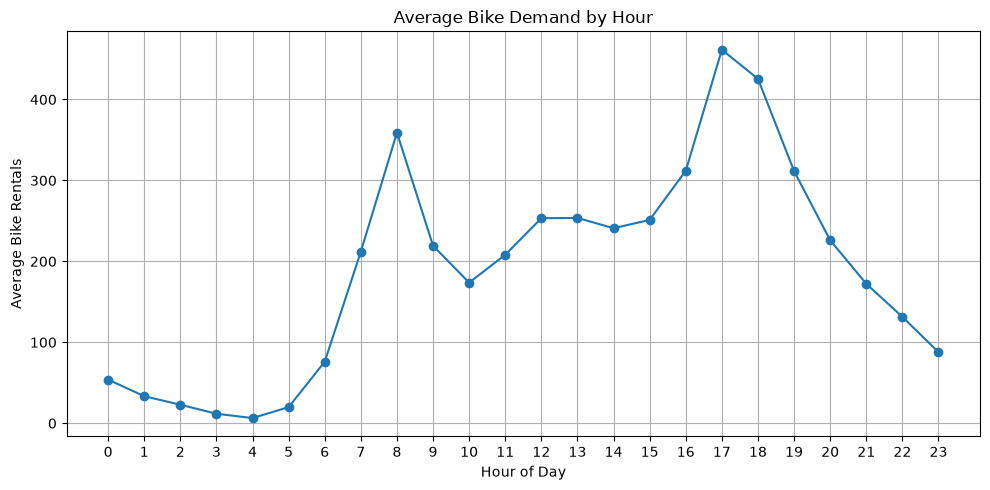

In [7]:
hourly_demand = (
    bike.groupby("hr")["cnt"]
        .mean()
)

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bike Rentals")
plt.title("Average Bike Demand by Hour")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

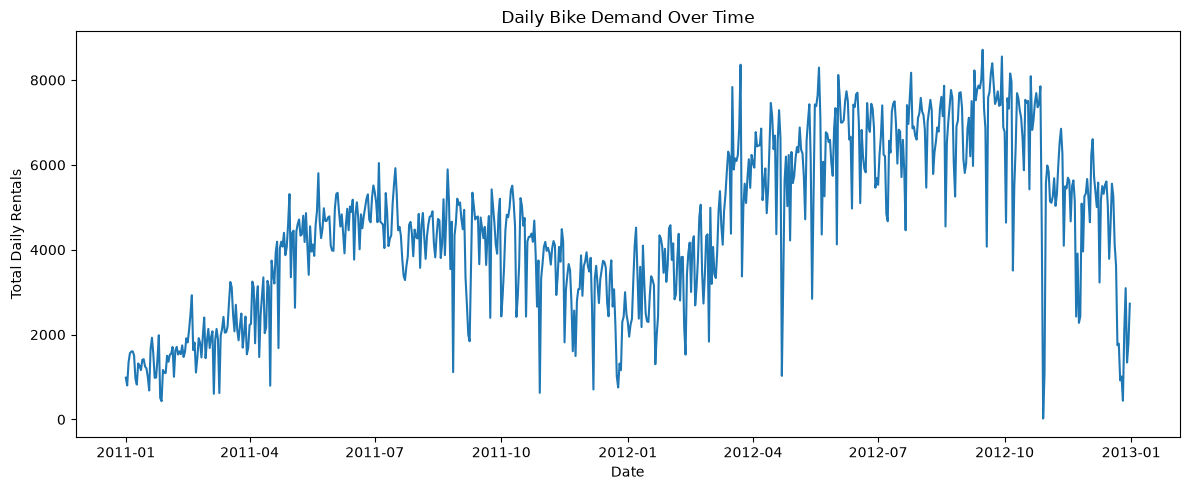

In [8]:
daily_demand = (
    bike.groupby("dteday")["cnt"]
        .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.xlabel("Date")
plt.ylabel("Total Daily Rentals")
plt.title("Daily Bike Demand Over Time")
plt.tight_layout()
plt.show()

### EDA Interpretation

Demand changes a lot depending on the hour and date. This means time-related features are important for predicting demand. Changes in demand over time could also affect model performance.

## Time-Based Train/Test Split

I used the first 80% of the data for training and the last 20% for testing. This keeps future observations out of the training data.

In [9]:
split_index = int(len(bike) * 0.80)

train = bike.iloc[:split_index].copy()
test = bike.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train["dteday"].min(), "to", train["dteday"].max())

print("\nTesting period:")
print(test["dteday"].min(), "to", test["dteday"].max())

assert train["dteday"].max() <= test["dteday"].min()

Training rows: 13903
Testing rows: 3476

Training period:
2011-01-01 00:00:00 to 2012-08-07 00:00:00

Testing period:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


## Feature Selection and Leakage Control

The models use calendar and weather features. `cnt`, `casual`, and `registered` are excluded to prevent target leakage. The preprocessing steps are inside a Pipeline and ColumnTransformer so they are fit using the training data only.

In [10]:
categorical_features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

numeric_features = [
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

feature_cols = categorical_features + numeric_features

X_train = train[feature_cols]
X_test = test[feature_cols]

y_train_reg = train["cnt"]
y_test_reg = test["cnt"]

y_train_cls = train["high_demand"]
y_test_cls = test["high_demand"]

print("Features:")
print(feature_cols)

print("\nNumber of features before encoding:", len(feature_cols))

Features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Number of features before encoding: 12


In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Baseline Linear Regression

Linear regression is used as the baseline model. I will use RMSE and R^2 to measure its performance.

In [12]:
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train_reg)

linear_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(
    mean_squared_error(y_test_reg, linear_pred)
)

linear_r2 = r2_score(
    y_test_reg,
    linear_pred
)

print("Linear Regression RMSE:", round(linear_rmse, 3))
print("Linear Regression R²:", round(linear_r2, 3))

Linear Regression RMSE: 133.835
Linear Regression R²: 0.632


## Linear Regression Diagnostic

The plot compares the predicted rental counts with the actual rental counts. Points closer to the diagonal line represent better predictions.

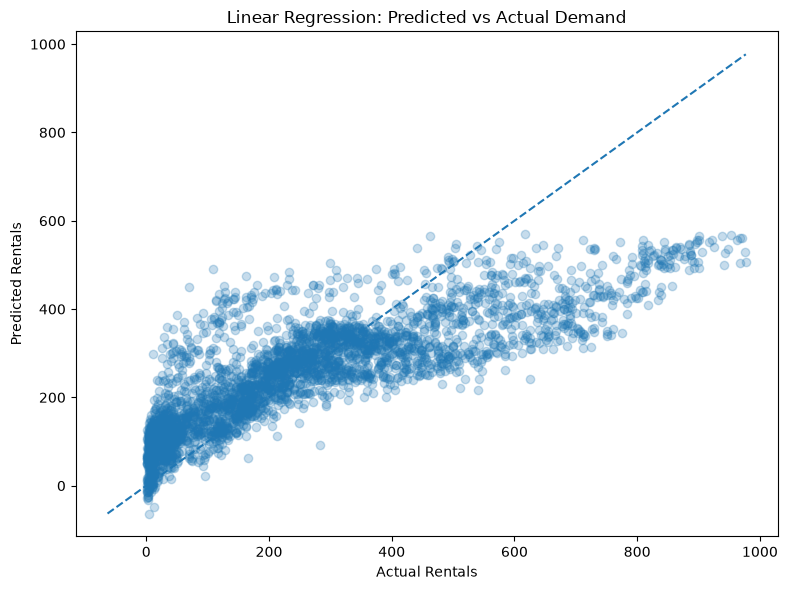

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_reg,
    linear_pred,
    alpha=0.25
)

min_value = min(y_test_reg.min(), linear_pred.min())
max_value = max(y_test_reg.max(), linear_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Rentals")
plt.ylabel("Predicted Rentals")
plt.title("Linear Regression: Predicted vs Actual Demand")
plt.tight_layout()
plt.show()

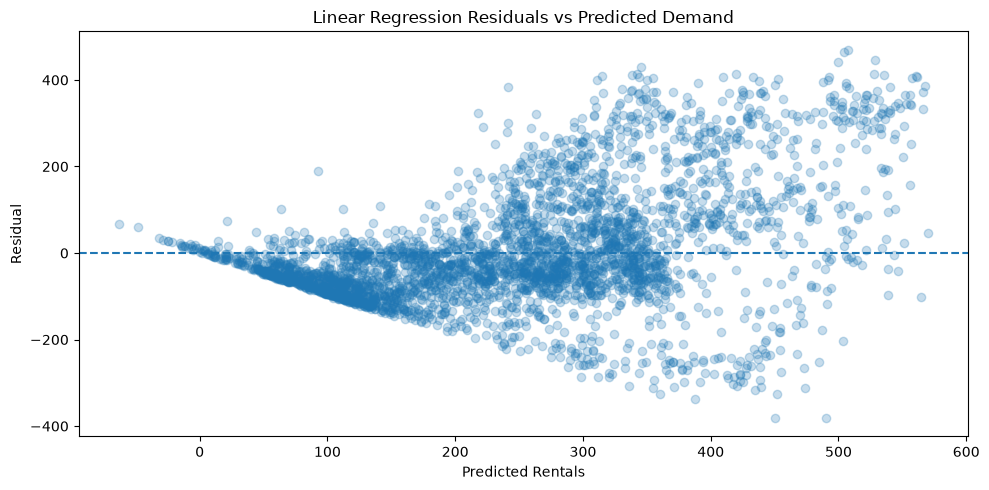

In [14]:
linear_residuals = y_test_reg - linear_pred

plt.figure(figsize=(10, 5))

plt.scatter(
    linear_pred,
    linear_residuals,
    alpha=0.25
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Rentals")
plt.ylabel("Residual")
plt.title("Linear Regression Residuals vs Predicted Demand")
plt.tight_layout()
plt.show()

### Residual Analysis

The residual plot helps show where the linear model is making larger errors. Large errors during high-demand periods would be especially important because they could affect bike availability and rebalancing.

## Regularized Regression

Ridge regression adds regularization to the linear model. I will compare it with the baseline using RMSE and R².

In [15]:
ridge_alphas = np.logspace(-3, 3, 13)

ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RidgeCV(
        alphas=ridge_alphas,
        cv=5
    ))
])

ridge_model.fit(X_train, y_train_reg)

ridge_pred = ridge_model.predict(X_test)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test_reg, ridge_pred)
)

ridge_r2 = r2_score(
    y_test_reg,
    ridge_pred
)

print("Ridge Regression RMSE:", round(ridge_rmse, 3))
print("Ridge Regression R²:", round(ridge_r2, 3))

print(
    "Selected alpha:",
    ridge_model.named_steps["model"].alpha_
)

Ridge Regression RMSE: 140.201
Ridge Regression R²: 0.596
Selected alpha: 100.0


In [16]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse
    ],
    "R2": [
        linear_r2,
        ridge_r2
    ]
})

regression_results

,Model,RMSE,R2
0,Linear Regression,133.835,0.632
1,Ridge Regression,140.201,0.596


### Regression Comparison

The model with lower RMSE has smaller prediction errors. R^2 shows how much of the variation in demand is explained by the model.

## Logistic Regression

Logistic regression is used to predict whether an hour has high demand. The model also gives probabilities, which can be used to test different alert thresholds.

In [17]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(
    X_train,
    y_train_cls
)

cls_prob = logistic_model.predict_proba(X_test)[:, 1]

cls_pred_050 = (
    cls_prob >= 0.50
).astype(int)

roc_auc = roc_auc_score(
    y_test_cls,
    cls_prob
)

print("Logistic Regression ROC AUC:", round(roc_auc, 4))

Logistic Regression ROC AUC: 0.9604


## Classification Evaluation

The confusion matrix shows correct and incorrect high-demand predictions. False negatives are important because they represent high-demand hours that were missed.

Confusion Matrix:
[[1088  279]
 [  90 2019]]


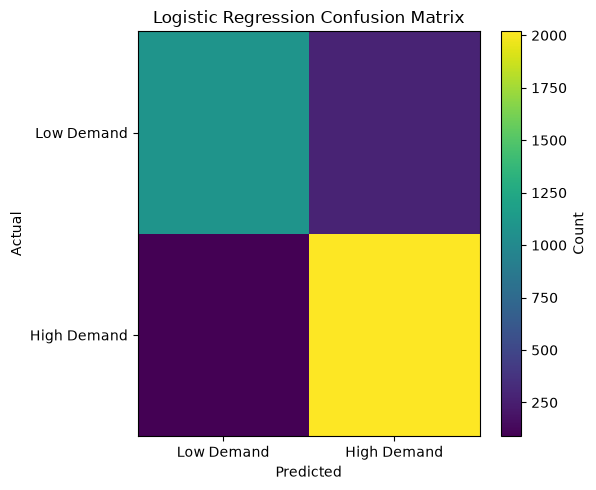

In [18]:
cm = confusion_matrix(
    y_test_cls,
    cls_pred_050
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, aspect="auto")

plt.xticks(
    [0, 1],
    ["Low Demand", "High Demand"]
)

plt.yticks(
    [0, 1],
    ["Low Demand", "High Demand"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.colorbar(label="Count")

plt.tight_layout()
plt.show()

In [19]:
print(
    classification_report(
        y_test_cls,
        cls_pred_050,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.92      0.80      0.86      1367
           1       0.88      0.96      0.92      2109

    accuracy                           0.89      3476
   macro avg       0.90      0.88      0.89      3476
weighted avg       0.90      0.89      0.89      3476



## Threshold Tuning

A 0.50 probability threshold is not always the best choice. Since missed high-demand periods can be costly, I will compare several thresholds and focus on recall.

In [20]:
thresholds = [
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80
]

threshold_results = []

for threshold in thresholds:
    predictions = (
        cls_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test_cls,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test_cls,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_test_cls,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,threshold,precision,recall,f1
0,0.200,0.828,0.992,0.903
1,0.300,0.852,0.980,0.911
2,0.400,0.866,0.968,0.914
3,0.500,0.879,0.957,0.916
4,0.600,0.893,0.945,0.918
5,0.700,0.907,0.930,0.918
6,0.800,0.922,0.897,0.910


In [21]:
recall_target = 0.90

eligible = threshold_results[
    threshold_results["recall"] >= recall_target
]

if len(eligible) > 0:
    deploy_threshold = (
        eligible.sort_values(
            ["precision", "threshold"],
            ascending=[False, True]
        )
        .iloc[0]["threshold"]
    )
else:
    deploy_threshold = (
        threshold_results.sort_values(
            ["recall", "precision"],
            ascending=[False, False]
        )
        .iloc[0]["threshold"]
    )

print("Selected deployment threshold:", deploy_threshold)

deploy_pred = (
    cls_prob >= deploy_threshold
).astype(int)

print(
    "Deployment precision:",
    round(
        precision_score(
            y_test_cls,
            deploy_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "Deployment recall:",
    round(
        recall_score(
            y_test_cls,
            deploy_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "Deployment F1:",
    round(
        f1_score(
            y_test_cls,
            deploy_pred,
            zero_division=0
        ),
        4
    )
)

Selected deployment threshold: 0.7
Deployment precision: 0.9066
Deployment recall: 0.9298
Deployment F1: 0.9181


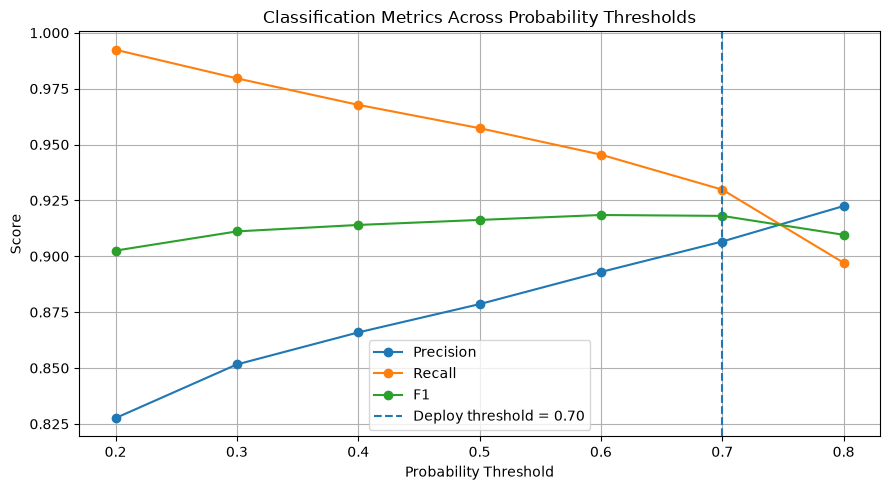

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    deploy_threshold,
    linestyle="--",
    label=f"Deploy threshold = {deploy_threshold:.2f}"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Classification Metrics Across Probability Thresholds")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Threshold Selection

Lower thresholds usually produce more alerts and higher recall. For this assignment, the threshold is chosen with a focus on catching as many high-demand periods as possible.

## Reproducibility

The notebook uses a fixed random seed of 42. The dataset source, preprocessing steps, model settings, and selected threshold should also be saved with the final model.

In [23]:
print("Reproducibility information")
print("-" * 40)
print("Random seed:", RANDOM_STATE)
print("Dataset URL:", DATA_URL)
print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Regression target: cnt")
print("Classification target: high_demand")
print("Deployment threshold:", deploy_threshold)

print("\nPackage versions")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Reproducibility information
----------------------------------------
Random seed: 42
Dataset URL: https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip
Training rows: 13903
Testing rows: 3476
Regression target: cnt
Classification target: high_demand
Deployment threshold: 0.7

Package versions
pandas: 2.3.3
numpy: 2.5.3


## Inference Cost

The models use a relatively small number of features, so predictions should be fairly quick. One-hot encoding increases the number of features, but the overall model is still manageable for hourly predictions.

## Monitoring and Drift

After deployment, the system should monitor missing values, unusual feature values, and changes in the input data. Model performance should also be checked over time using RMSE, R², ROC AUC, precision, and recall.

## Limitations and Next Steps

The dataset does not include every factor that can affect bike demand, such as special events or transportation disruptions. Future work could test additional features, rolling time-based validation, and nonlinear models. The high-demand threshold could also be changed using actual staffing and bike availability requirements.

## Experiment Log

The table below records the main models and their results.

In [24]:
experiment_log = pd.DataFrame([
    {
        "task": "Regression",
        "model": "Linear Regression",
        "metric_1": "RMSE",
        "value_1": linear_rmse,
        "metric_2": "R2",
        "value_2": linear_r2
    },
    {
        "task": "Regression",
        "model": "Ridge Regression",
        "metric_1": "RMSE",
        "value_1": ridge_rmse,
        "metric_2": "R2",
        "value_2": ridge_r2
    },
    {
        "task": "Classification",
        "model": "Logistic Regression",
        "metric_1": "ROC AUC",
        "value_1": roc_auc,
        "metric_2": "Threshold",
        "value_2": deploy_threshold
    }
])

experiment_log

,task,model,metric_1,value_1,metric_2,value_2
0,Regression,Linear Regression,RMSE,133.835,R2,0.632
1,Regression,Ridge Regression,RMSE,140.201,R2,0.596
2,Classification,Logistic Regression,ROC AUC,0.960,Threshold,0.700


## Final Results Summary

This assignment compared linear and Ridge regression for demand prediction and logistic regression for high-demand alerts. The models were evaluated using a time-based split and leakage-resistant preprocessing. The results provide a baseline for bike-demand forecasting, but additional validation and monitoring would be needed before using the models in production.